# Day 2: South American Natural and Mixed UNESCO Heritage Sites

Data Source: https://whc.unesco.org/en/interactive-map/

Picture Source: https://unsplash.com/photos/ancient-inca-citadel-of-machu-picchu-in-peru-iMWos9jS3oE

In [43]:
import pandas as pd
import numpy as np
import json, os, urllib.request
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from scipy.sparse.csgraph import minimum_spanning_tree

### 1. Filter for natural and mixed sites in South America from the UNESCO's World Heritage List

In [13]:
# load UNESCO's World Heritage list
df = pd.read_excel("UNESCO.xlsx")

C:\Users\User\anaconda3\envs\myenv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [17]:
# South American countries by ISO code
# (some sites span several countries, e.g. "ar,br", so we check each code)
south_america = ["ar", "bo", "br", "cl", "co", "ec", "gy", "py", "pe", "sr", "uy", "ve"]

is_sa = df["iso_code"].fillna("").apply(
    lambda codes: any(c.strip() in south_america for c in codes.split(","))
)

In [19]:
# Keep natural and mixed sites only
sites = df[is_sa & df["category"].isin(["Natural", "Mixed"])].copy()

In [21]:
# Tidy up: shorter country names, useful columns only
sites["country"] = sites["states_name_en"].str.replace(r" \(.*\)", "", regex=True)
sites = (
    sites[["id_no", "name_en", "country", "category", "date_inscribed", "latitude", "longitude"]]
    .rename(columns={"name_en": "name", "date_inscribed": "year"})
    .sort_values(["country", "name"])
    .reset_index(drop=True)
)

In [23]:
print(len(sites), "sites")
sites

27 sites


,id_no,name,country,category,year,latitude,longitude
0,303,Iguazu National Park,Argentina,Natural,1984,-25.577357,-54.286073
1,966,Ischigualasto / Talampaya Natural Parks,Argentina,Natural,2000,-30.000000,-68.000000
2,1526,Los Alerces National Park,Argentina,Natural,2017,-42.852800,-71.872800
3,145,Los Glaciares National Park,Argentina,Natural,1981,-50.000000,-73.249440
4,937,Península Valdés,Argentina,Natural,1999,-42.500000,-64.000000
5,967,Noel Kempff Mercado National Park,Bolivia,Natural,2000,-14.266670,-60.866670
6,893,Atlantic Forest South-East Reserves,Brazil,Natural,1999,-24.166670,-48.000000
7,1000,Brazilian Atlantic Islands: Fernando de Noronh...,Brazil,Natural,2001,-3.857944,-32.425111
8,998,Central Amazon Conservation Complex,Brazil,Natural,2000,-2.333333,-62.008333
9,1035,Cerrado Protected Areas: Chapada dos Veadeiros...,Brazil,Natural,2001,-14.005694,-47.684611


### 2. Plot points on a map

In [31]:
# Natural Earth land outlines (downloaded once, reused if already there)
land_file = "ne_50m_land.geojson"
if not os.path.exists(land_file):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_land.geojson",
        land_file)
land = json.load(open(land_file, encoding="utf-8"))

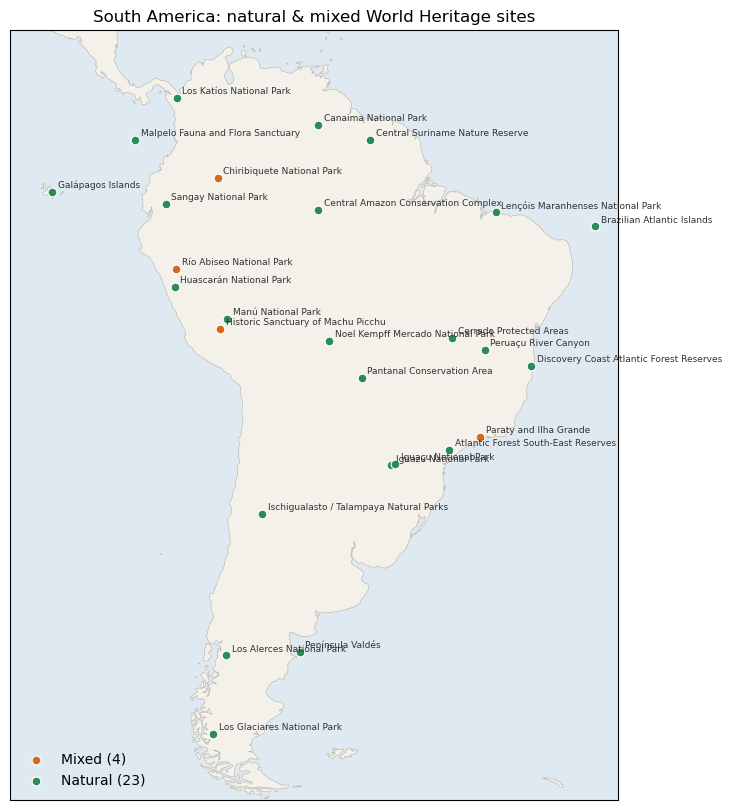

In [33]:
# Plot the map
fig, ax = plt.subplots(figsize=(8, 10))
ax.set_facecolor("#dfe9f2")

for feat in land["features"]:
    g = feat["geometry"]
    polys = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
    for poly in polys:
        ax.add_patch(Polygon(poly[0], closed=True, facecolor="#f4f1ea",
                             edgecolor="#b8b2a6", linewidth=0.4))

colours = {"Natural": "#2e8b57", "Mixed": "#d2691e"}
for cat, grp in sites.groupby("category"):
    ax.scatter(grp["longitude"], grp["latitude"], s=40, color=colours[cat],
               edgecolor="white", linewidth=0.8, zorder=3, label=f"{cat} ({len(grp)})")

for _, r in sites.iterrows():
    short = r["name"].split(":")[0].split(" – ")[0]   # trim long names
    ax.annotate(short, (r["longitude"], r["latitude"]), xytext=(4, 3),
                textcoords="offset points", fontsize=6.5, color="#333")

ax.set_xlim(-95, -30)
ax.set_ylim(-56, 14)
ax.set_aspect(1 / 0.85)   # rough correction so the continent isn't squashed
ax.legend(loc="lower left", frameon=False)
ax.set_title("South America: natural & mixed World Heritage sites", fontsize=12)
ax.set_xticks([]); ax.set_yticks([])
plt.show()

### 3. Minimum Spanning Tree

In [45]:
# Short labels for printing / plotting
sites["short"] = sites["name"].str.split(":").str[0].str.split(" – ").str[0]

# Great-circle distances (km) between every pair of sites
lat = np.radians(sites["latitude"].to_numpy())
lon = np.radians(sites["longitude"].to_numpy())
dlat = lat[:, None] - lat[None, :]
dlon = lon[:, None] - lon[None, :]
a = np.sin(dlat / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(dlon / 2) ** 2
dist_km = 2 * 6371 * np.arcsin(np.sqrt(a))

# Minimum spanning tree: connects all sites with the least total distance
mst = minimum_spanning_tree(dist_km).tocoo()
edges = pd.DataFrame({
    "from": sites["short"].to_numpy()[mst.row],
    "to": sites["short"].to_numpy()[mst.col],
    "km": mst.data.round(0).astype(int),
}).sort_values("km", ascending=False).reset_index(drop=True)

print(f"{len(edges)} links, total {edges['km'].sum():,} km")
edges

26 links, total 19,962 km


,from,to,km
0,Iguazu National Park,Ischigualasto / Talampaya Natural Parks,1435
1,Ischigualasto / Talampaya Natural Parks,Península Valdés,1435
2,Cerrado Protected Areas,Lençóis Maranhenses National Park,1373
3,Central Amazon Conservation Complex,Chiribiquete National Park,1241
4,Noel Kempff Mercado National Park,Manú National Park,1199
5,Brazilian Atlantic Islands,Lençóis Maranhenses National Park,1190
6,Malpelo Fauna and Flora Sanctuary,Galápagos Islands,1118
7,Iguazu National Park,Pantanal Conservation Area,936
8,Paraty and Ilha Grande,Peruaçu River Canyon,885
9,Central Amazon Conservation Complex,Canaima National Park,853


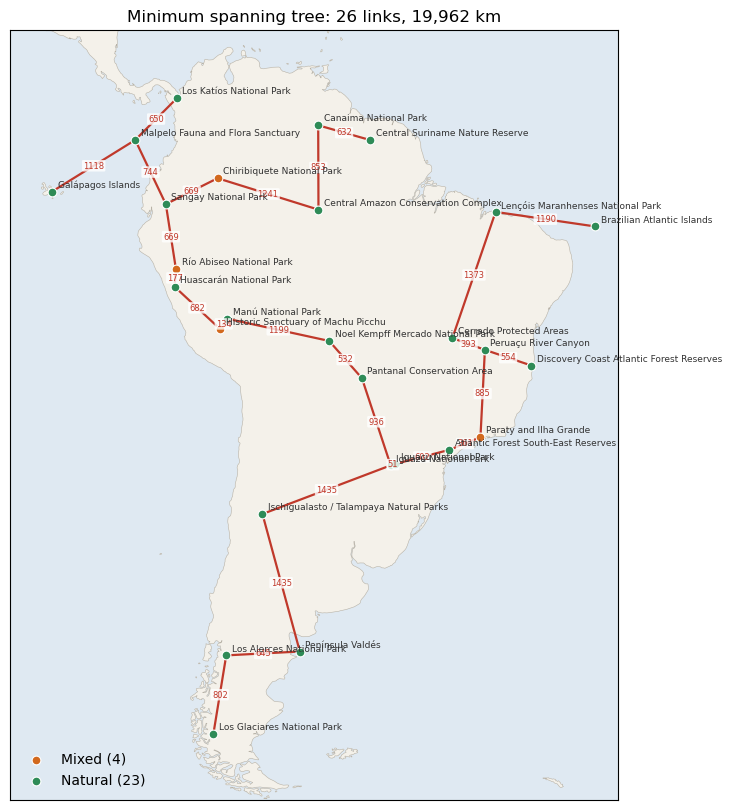

In [47]:
# Plot the Minimum Spanning Tree
land = json.load(open("ne_50m_land.geojson", encoding="utf-8"))

fig, ax = plt.subplots(figsize=(8, 10))
ax.set_facecolor("#dfe9f2")
for feat in land["features"]:
    g = feat["geometry"]
    polys = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
    for poly in polys:
        ax.add_patch(Polygon(poly[0], closed=True, facecolor="#f4f1ea",
                             edgecolor="#b8b2a6", linewidth=0.4))

# MST links with distance labels
for i, j, km in zip(mst.row, mst.col, mst.data):
    ax.plot(sites.loc[[i, j], "longitude"], sites.loc[[i, j], "latitude"],
            color="#c0392b", linewidth=1.6, zorder=2)
    mx, my = sites.loc[[i, j], "longitude"].mean(), sites.loc[[i, j], "latitude"].mean()
    ax.text(mx, my, f"{km:.0f}", fontsize=6, color="#c0392b", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8), zorder=4)

colours = {"Natural": "#2e8b57", "Mixed": "#d2691e"}
for cat, grp in sites.groupby("category"):
    ax.scatter(grp["longitude"], grp["latitude"], s=40, color=colours[cat],
               edgecolor="white", linewidth=0.8, zorder=3, label=f"{cat} ({len(grp)})")
for _, r in sites.iterrows():
    ax.annotate(r["short"], (r["longitude"], r["latitude"]), xytext=(4, 3),
                textcoords="offset points", fontsize=6.5, color="#333", zorder=5)

ax.set_xlim(-95, -30)
ax.set_ylim(-56, 14)
ax.set_aspect(1 / 0.85)
ax.legend(loc="lower left", frameon=False)
ax.set_title(f"Minimum spanning tree: {len(edges)} links, {edges['km'].sum():,} km", fontsize=12)
ax.set_xticks([]); ax.set_yticks([])
plt.show()

### 4. Save the outline for designing in Canva

In [51]:
land = json.load(open("ne_50m_land.geojson", encoding="utf-8"))

# Same extent and size for both maps, so they line up exactly in Canva
XMIN, XMAX, YMIN, YMAX = -95, -22, -56, 14
ASPECT = 1 / 0.85            # stretch latitude a little so the shape looks natural
WIDTH_IN = 10
DPI = 300                    # 10 in x 300 dpi = 3000 px wide
height_in = WIDTH_IN * (YMAX - YMIN) * ASPECT / (XMAX - XMIN)

OUTLINE = "#5a6b7b"          # change to suit your Canva design
LINE_W = 0.8

def base_map():
    fig = plt.figure(figsize=(WIDTH_IN, height_in), dpi=DPI)
    ax = fig.add_axes([0, 0, 1, 1])          # no margins
    for feat in land["features"]:
        g = feat["geometry"]
        polys = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
        for poly in polys:
            ax.add_patch(Polygon(poly[0], closed=True, facecolor="none",
                                 edgecolor=OUTLINE, linewidth=LINE_W))
    ax.set_xlim(XMIN, XMAX)
    ax.set_ylim(YMIN, YMAX)
    ax.set_aspect(ASPECT)
    ax.axis("off")
    return fig, ax

# Map 1: outline only
fig, ax = base_map()
fig.savefig("sa_outline.png", dpi=DPI, transparent=True)
plt.close(fig)

# Map 2: outline + sites + labels
fig, ax = base_map()
colours = {"Natural": "#2e8b57", "Mixed": "#d2691e"}
for cat, grp in sites.groupby("category"):
    ax.scatter(grp["longitude"], grp["latitude"], s=25, color=colours[cat],
               edgecolor="white", linewidth=0.6, zorder=3)
for _, r in sites.iterrows():
    ax.annotate(r["short"], (r["longitude"], r["latitude"]), xytext=(4, 3),
                textcoords="offset points", fontsize=6, color="#333", zorder=4)
fig.savefig("sa_sites.png", dpi=DPI, transparent=True)
plt.close(fig)

print("Saved sa_outline.png and sa_sites.png")

Saved sa_outline.png and sa_sites.png
